<a href="https://colab.research.google.com/github/MassEgo88/OIBSIP/blob/main/DataScience-Task2-UnemploymentAnalysis/Unemployment_Analysis__in_India.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# PROJECT 2: UNEMPLOYMENT ANALYSIS
# ADVANCED END-TO-END DATA SCIENCE
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

RANDOM_STATE = 42

print("All libraries imported successfully!")
print("Project 2: Unemployment Analysis")

All libraries imported successfully!
Project 2: Unemployment Analysis


In [2]:
 # CELL 2 - Upload dataset

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving Unemployment in India.csv to Unemployment in India.csv
Dataset uploaded successfully!


In [3]:
#CELL 3 — Load dataset

import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

df.columns = df.columns.str.strip()

print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 records:")
display(df.head(10))

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

DATASET LOADED SUCCESSFULLY
Dataset shape: (768, 7)

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

First 10 records:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural
9,Andhra Pradesh,29-02-2020,Monthly,5.91,11723617.0,42.83,Rural



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Statistical summary:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


In [4]:
#CELL 4 — Initial data inspection

print("MISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nUNIQUE VALUES PER COLUMN")
display(df.nunique())

print("\nDATA TYPES")
display(df.dtypes)

print("\nDATASET DIMENSIONS")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

MISSING VALUES


,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



DUPLICATE RECORDS
27

UNIQUE VALUES PER COLUMN


,0
Region,28
Date,14
Frequency,2
Estimated Unemployment Rate (%),624
Estimated Employed,740
Estimated Labour Participation Rate (%),626
Area,2



DATA TYPES


,0
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object



DATASET DIMENSIONS
Rows: 768
Columns: 7


##DATA CLEANING AND PREPARATION

In [5]:
# CELL 5 - Clean column names and text values

df.columns = df.columns.str.strip()

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

print("Column and text cleaning completed.")

print(df.columns.tolist())

Column and text cleaning completed.
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [6]:
#CELL 6 — Convert date and numerical columns

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
    dayfirst=True
)

numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Date and numerical conversion completed.")

display(df.head())

Date and numerical conversion completed.


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [7]:
# CELL 7 — Remove duplicates and invalid records

print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Remove records without a valid date or target
df = df.dropna(
    subset=[
        "Date",
        "Estimated Unemployment Rate (%)"
    ]
).copy()

# Remove impossible negative measurements
df = df[
    (df["Estimated Unemployment Rate (%)"] >= 0) &
    (df["Estimated Employed"] >= 0) &
    (df["Estimated Labour Participation Rate (%)"] >= 0)
].copy()

print("Duplicates after cleaning:", df.duplicated().sum())

print("Cleaned dataset shape:", df.shape)

display(df.head())

Duplicates before cleaning: 27
Duplicates after cleaning: 0
Cleaned dataset shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [8]:
# CELL 8 — Missing-value analysis

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

print("\nRemaining missing values:")
print(df.isnull().sum().sum())

,Missing_Count,Missing_Percentage
Region,0,0.0
Date,0,0.0
Frequency,0,0.0
Estimated Unemployment Rate (%),0,0.0
Estimated Employed,0,0.0
Estimated Labour Participation Rate (%),0,0.0
Area,0,0.0



Remaining missing values:
0


In [9]:
# CELL 9 — Feature engineering

df["Year"] = df["Date"].dt.year

df["Month"] = df["Date"].dt.month

df["Month_Name"] = df["Date"].dt.month_name()

df["Quarter"] = df["Date"].dt.quarter

df["COVID_Period"] = np.where(
    df["Date"] >= pd.Timestamp("2020-03-01"),
    "COVID Period",
    "Pre-COVID Period"
)

print("Feature engineering completed.")

display(df.head(10))

Feature engineering completed.


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Year,Month,Month_Name,Quarter,COVID_Period
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019,5,May,2,Pre-COVID Period
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019,6,June,2,Pre-COVID Period
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019,7,July,3,Pre-COVID Period
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,2019,8,August,3,Pre-COVID Period
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,2019,9,September,3,Pre-COVID Period
5,Andhra Pradesh,2019-10-31,Monthly,3.52,12017412.0,43.01,Rural,2019,10,October,4,Pre-COVID Period
6,Andhra Pradesh,2019-11-30,Monthly,4.12,11397681.0,41.00,Rural,2019,11,November,4,Pre-COVID Period
7,Andhra Pradesh,2019-12-31,Monthly,4.38,12528395.0,45.14,Rural,2019,12,December,4,Pre-COVID Period
8,Andhra Pradesh,2020-01-31,Monthly,4.84,12016676.0,43.46,Rural,2020,1,January,1,Pre-COVID Period
9,Andhra Pradesh,2020-02-29,Monthly,5.91,11723617.0,42.83,Rural,2020,2,February,1,Pre-COVID Period


In [10]:
# CELL 10 — Final data validation

print("FINAL DATA VALIDATION")
print("=" * 50)

print("Total records:", len(df))

print("Total columns:", len(df.columns))

print("Date range:")
print(df["Date"].min(), "to", df["Date"].max())

print("Number of regions:", df["Region"].nunique())

print("\nRemaining missing values:")
display(df.isnull().sum())

print("\nUnemployment rate range:")
print(
    df["Estimated Unemployment Rate (%)"].min(),
    "to",
    df["Estimated Unemployment Rate (%)"].max()
)

FINAL DATA VALIDATION
Total records: 740
Total columns: 12
Date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00
Number of regions: 28

Remaining missing values:


,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0
Year,0
Month,0
Month_Name,0



Unemployment rate range:
0.0 to 76.74


##  EXPLORATORY DATA ANALYSIS (EDA)

In [11]:
# CELL 11 — Descriptive statistics

print("UNEMPLOYMENT DESCRIPTIVE STATISTICS")

display(
    df["Estimated Unemployment Rate (%)"].describe()
)

print("\nAverage unemployment rate:")

print(
    round(
        df["Estimated Unemployment Rate (%)"].mean(),
        2
    ),
    "%"
)

print("\nMedian unemployment rate:")

print(
    round(
        df["Estimated Unemployment Rate (%)"].median(),
        2
    ),
    "%"
)

UNEMPLOYMENT DESCRIPTIVE STATISTICS


,Estimated Unemployment Rate (%)
count,740.000000
mean,11.787946
std,10.721298
min,0.000000
25%,4.657500
50%,8.350000
75%,15.887500
max,76.740000



Average unemployment rate:
11.79 %

Median unemployment rate:
8.35 %


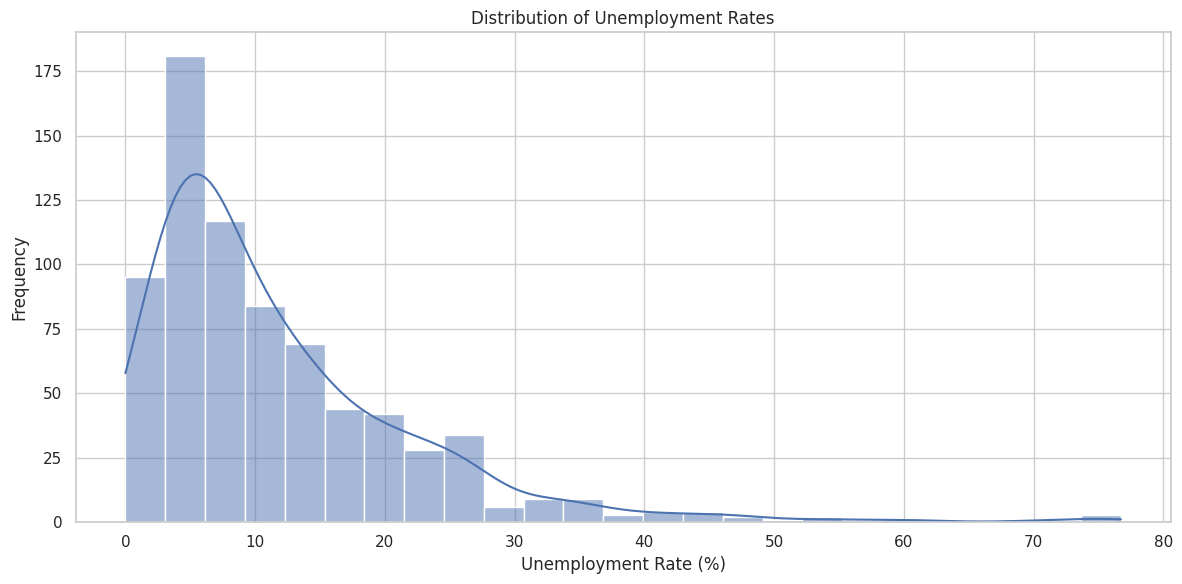

In [12]:
# CELL 12 — Unemployment distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Estimated Unemployment Rate (%)",
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rates")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

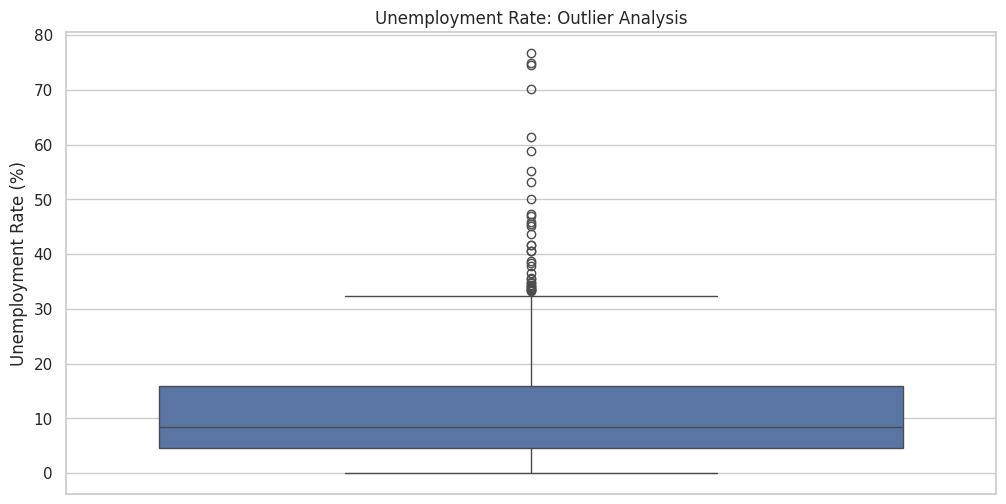

In [13]:
# CELL 13 — Unemployment boxplot

plt.figure(figsize=(12, 6))

sns.boxplot(
    y=df["Estimated Unemployment Rate (%)"]
)

plt.title("Unemployment Rate: Outlier Analysis")
plt.ylabel("Unemployment Rate (%)")

plt.show()

,Average,Median,Maximum,Minimum,Standard_Deviation,Observations
Region,,,,,,
Tripura,28.350357,27.310,43.64,14.71,6.058335,28
Haryana,26.283214,25.060,46.89,14.54,7.797119,28
Jharkhand,20.585000,17.285,70.17,5.01,16.674746,28
Bihar,18.918214,15.010,58.77,8.87,12.634987,28
Himachal Pradesh,18.540357,18.355,50.00,1.12,9.607612,28
Delhi,16.495357,15.020,45.78,9.33,6.788172,28
Jammu & Kashmir,16.188571,16.000,24.06,2.22,5.506308,21
Chandigarh,15.991667,17.510,22.05,7.22,5.508220,12
Rajasthan,14.058214,13.660,35.53,4.03,5.932577,28


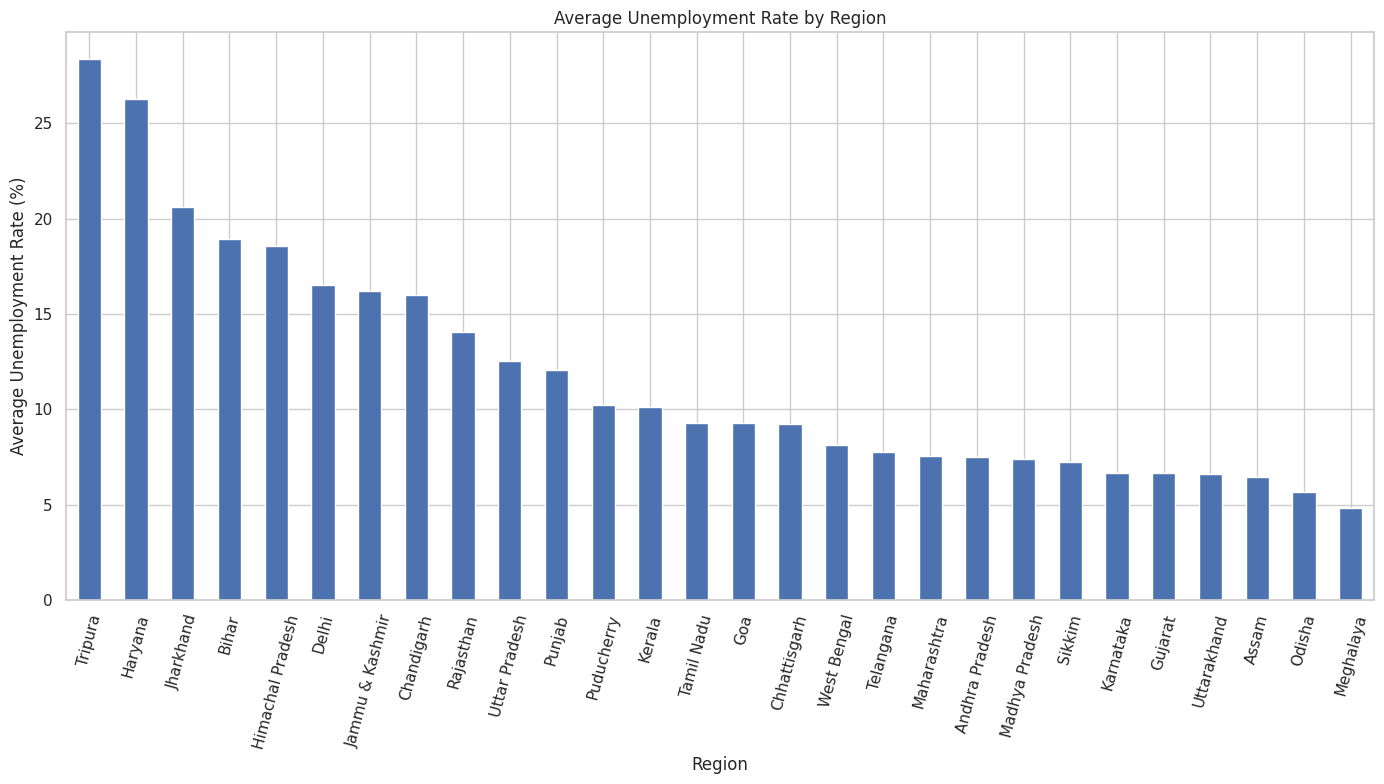

In [14]:
# CELL 14 — Regional unemployment analysis

regional_unemployment = (
    df.groupby("Region")[
        "Estimated Unemployment Rate (%)"
    ]
    .agg(["mean", "median", "max", "min", "std", "count"])
    .sort_values("mean", ascending=False)
)

regional_unemployment.columns = [
    "Average",
    "Median",
    "Maximum",
    "Minimum",
    "Standard_Deviation",
    "Observations"
]

display(regional_unemployment)

plt.figure(figsize=(14, 8))

regional_unemployment["Average"].plot(
    kind="bar"
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

,Average,Median,Maximum,Minimum,Standard_Deviation,Observations
Region,,,,,,
Tripura,28.350357,27.310,43.64,14.71,6.058335,28
Haryana,26.283214,25.060,46.89,14.54,7.797119,28
Jharkhand,20.585000,17.285,70.17,5.01,16.674746,28
Bihar,18.918214,15.010,58.77,8.87,12.634987,28
Himachal Pradesh,18.540357,18.355,50.00,1.12,9.607612,28


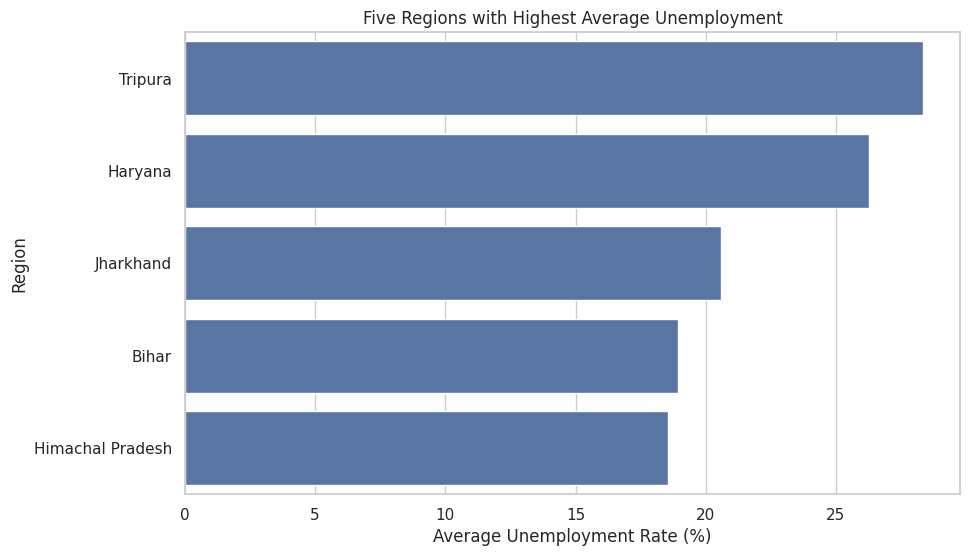

In [15]:
# CELL 15 — Top five regions

top_regions = regional_unemployment.head(5)

display(top_regions)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_regions["Average"],
    y=top_regions.index
)

plt.title("Five Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.show()

,Average,Median,Maximum,Minimum,Standard_Deviation,Observations
Region,,,,,,
Meghalaya,4.798889,3.730,17.39,0.24,4.102673,27
Odisha,5.657857,3.870,24.48,1.78,5.553891,28
Assam,6.428077,5.435,11.17,0.00,3.008218,26
Uttarakhand,6.582963,5.560,17.36,1.63,3.321334,27
Gujarat,6.663929,5.420,25.94,1.41,4.682053,28


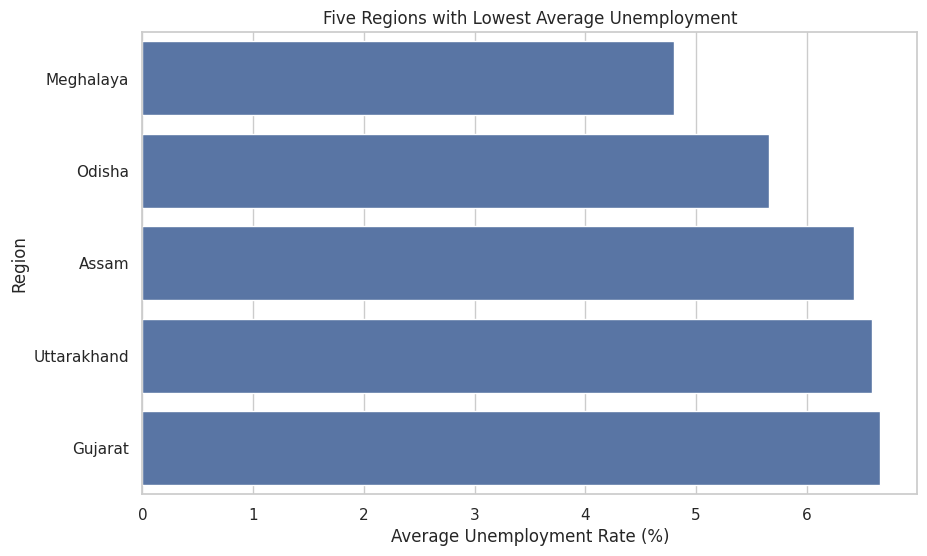

In [16]:
# CELL 16 — Five regions with lowest unemployment

lowest_regions = regional_unemployment.tail(5).sort_values(
    "Average"
)

display(lowest_regions)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=lowest_regions["Average"],
    y=lowest_regions.index
)

plt.title("Five Regions with Lowest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.show()

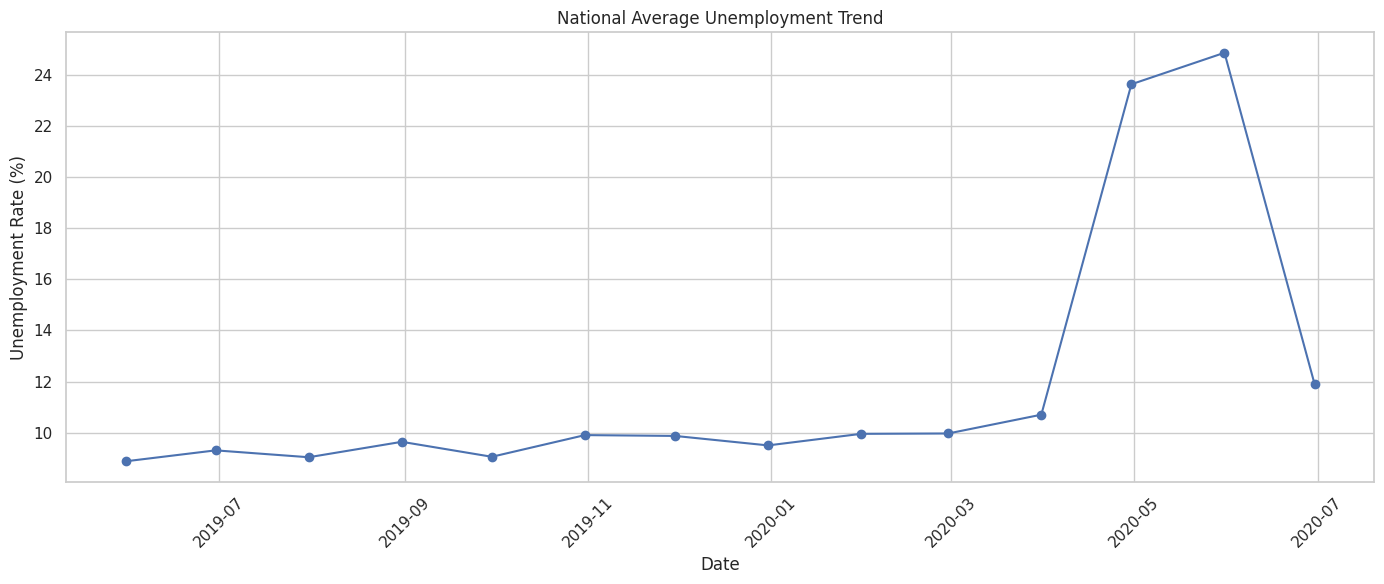

In [17]:
# CELL 17 — Time-series analysis

time_series = (
    df.groupby("Date")[
        "Estimated Unemployment Rate (%)"
    ]
    .mean()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    time_series.index,
    time_series.values,
    marker="o"
)

plt.title("National Average Unemployment Trend")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

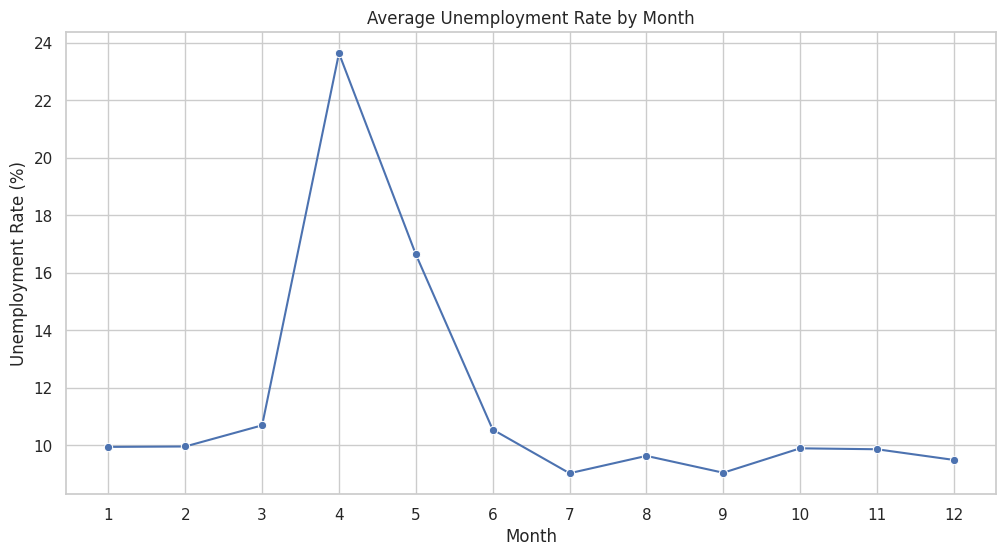

In [18]:
# CELL 18 — Monthly unemployment patterns

monthly_patterns = (
    df.groupby("Month")[
        "Estimated Unemployment Rate (%)"
    ].mean()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_patterns.index,
    y=monthly_patterns.values,
    marker="o"
)

plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(range(1, 13))

plt.show()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


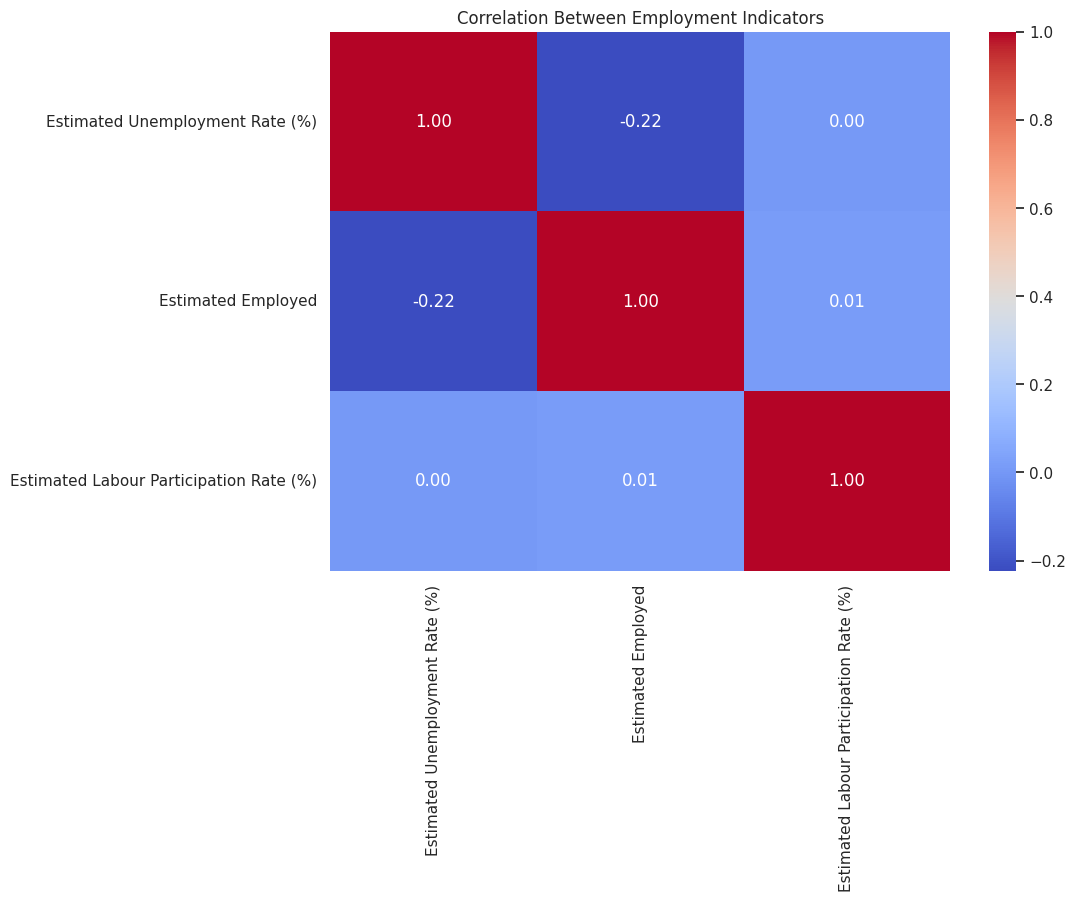

In [19]:
# CELL 19 — Correlation analysis

correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[correlation_columns].corr()

display(correlation)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Employment Indicators")

plt.show()

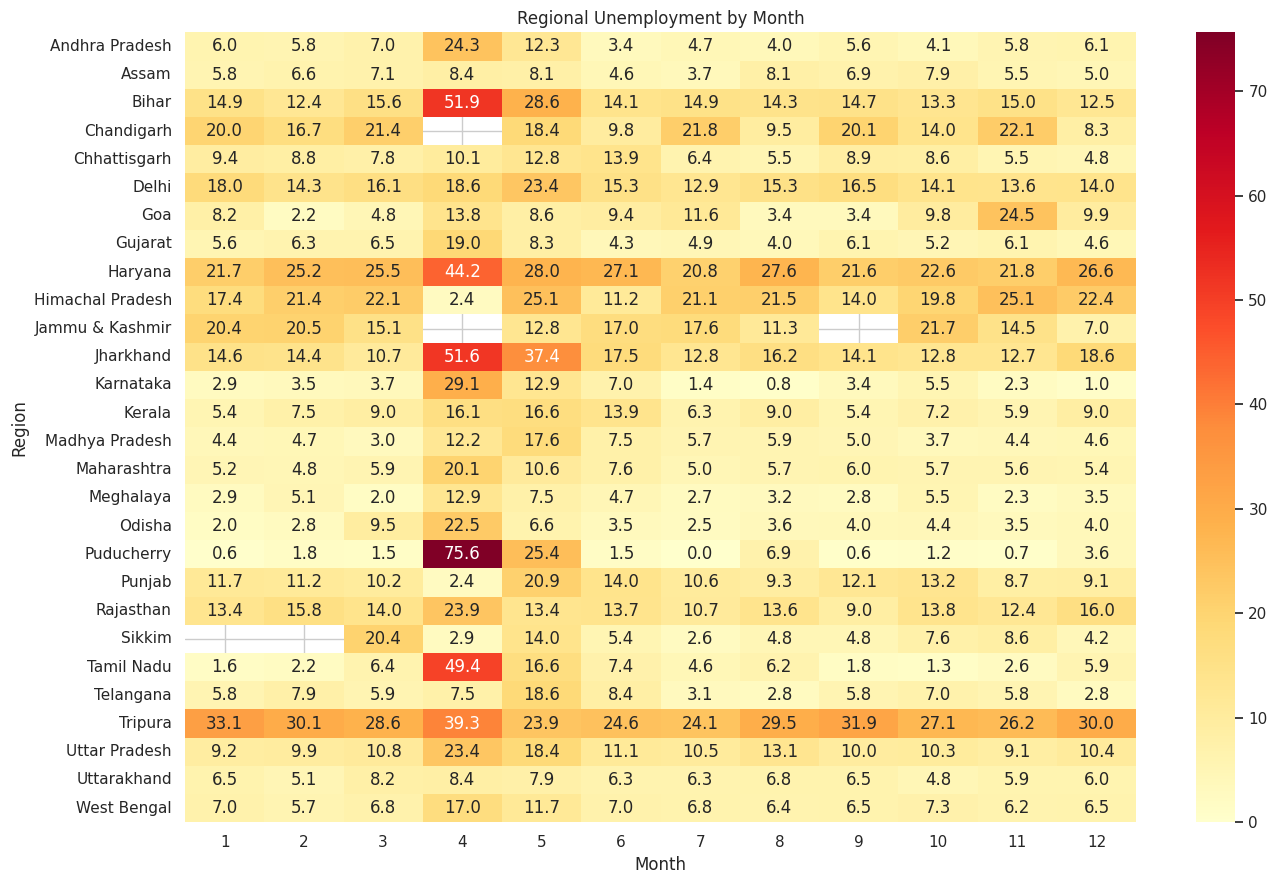

In [20]:
# CELL 20 — Regional comparison using a heatmap

regional_monthly = df.pivot_table(
    index="Region",
    columns="Month",
    values="Estimated Unemployment Rate (%)",
    aggfunc="mean"
)

plt.figure(figsize=(14, 9))

sns.heatmap(
    regional_monthly,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f"
)

plt.title("Regional Unemployment by Month")

plt.xlabel("Month")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

## STATISTICAL ANALYSIS

In [21]:
# CELL 21 — Hypothesis testing

# We will compare regional unemployment averages before March 2020 and from March 2020 onwards.

# The comparison uses regions observed in both periods.

pre_covid = (
    df[df["Date"] < "2020-03-01"]
    .groupby("Region")[
        "Estimated Unemployment Rate (%)"
    ].mean()
)

covid = (
    df[df["Date"] >= "2020-03-01"]
    .groupby("Region")[
        "Estimated Unemployment Rate (%)"
    ].mean()
)

paired = pd.concat(
    [pre_covid, covid],
    axis=1,
    keys=["Pre_COVID", "COVID"]
).dropna()

print("Matched regions:", len(paired))

if len(paired) >= 2:

    t_stat, p_value = stats.ttest_rel(
        paired["COVID"],
        paired["Pre_COVID"]
    )

    print("T-statistic:", t_stat)
    print("P-value:", p_value)

    if p_value < 0.05:
        print(
            "A statistically significant difference "
            "was detected."
        )
    else:
        print(
            "No statistically significant difference "
            "was detected."
        )

else:
    print("Insufficient matched regions.")

Matched regions: 28
T-statistic: 4.751440670511318
P-value: 5.94048904008613e-05
A statistically significant difference was detected.


In [22]:
# CELL 22 — Effect size

if len(paired) >= 2:

    differences = (
        paired["COVID"] - paired["Pre_COVID"]
    )

    mean_difference = differences.mean()

    std_difference = differences.std(ddof=1)

    if std_difference > 0:

        cohens_d = mean_difference / std_difference

        print("Mean difference:", mean_difference)

        print("Cohen's d:", cohens_d)

    else:
        print("Effect size cannot be calculated.")

else:
    print("Insufficient data for effect size.")

Mean difference: 7.87837756729486
Cohen's d: 0.8979378845322098


## ADVANCED FEATURE ENGINEERING

In [23]:
# CELL 23 — Prepare machine-learning features

# We will estimate unemployment rates using employment, labour participation, regional and calendar information.

# This is an estimation task, not a claim that we can predict future unemployment using information unavailable at prediction time.

model_df = df.dropna(
    subset=[
        "Estimated Unemployment Rate (%)",
        "Date",
        "Region"
    ]
).copy()

features = [
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Region",
    "Month",
    "Year"
]

target = "Estimated Unemployment Rate (%)"

X = model_df[features]

y = model_df[target]

print("Feature dataset shape:", X.shape)

print("Target shape:", y.shape)

display(X.head())

Feature dataset shape: (740, 5)
Target shape: (740,)


,Estimated Employed,Estimated Labour Participation Rate (%),Region,Month,Year
0,11999139.0,43.24,Andhra Pradesh,5,2019
1,11755881.0,42.05,Andhra Pradesh,6,2019
2,12086707.0,43.50,Andhra Pradesh,7,2019
3,12285693.0,43.97,Andhra Pradesh,8,2019
4,12256762.0,44.68,Andhra Pradesh,9,2019


In [24]:
# CELL 24 — Chronological train-test split

model_df = model_df.sort_values("Date").reset_index(
    drop=True
)

X = model_df[features]

y = model_df[target]

unique_dates = sorted(model_df["Date"].unique())

if len(unique_dates) < 5:
    raise ValueError(
        "Insufficient unique dates for chronological evaluation."
    )

split_position = int(len(unique_dates) * 0.8)

cutoff_date = unique_dates[split_position]

train_mask = model_df["Date"] < cutoff_date

test_mask = model_df["Date"] >= cutoff_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("Training period ends:", X_train.index.max())

print("Test begins at:", cutoff_date)

Training records: 588
Testing records: 152
Training period ends: 587
Test begins at: 2020-04-30 00:00:00


In [25]:
# CELL 25 — Build preprocessing pipeline

numeric_features = [
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Month",
    "Year"
]

categorical_features = ["Region"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [26]:
# CELL 26 — Linear Regression model

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


In [27]:
# CELL 27 — Random Forest model

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=10,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest trained successfully.")

Random Forest trained successfully.


##  MODEL EVALUATION

In [28]:
# CELL 28 — Evaluate Linear Regression

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("LINEAR REGRESSION RESULTS")
print("=" * 40)

print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2:", round(linear_r2, 4))

LINEAR REGRESSION RESULTS
MAE: 12.8673
RMSE: 18.8403
R2: -0.3652


In [29]:
# CELL 29 — Evaluate Random Forest

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("RANDOM FOREST RESULTS")
print("=" * 40)

print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2:", round(rf_r2, 4))

RANDOM FOREST RESULTS
MAE: 12.7995
RMSE: 18.6783
R2: -0.3419


,Model,MAE,RMSE,R2
0,Linear Regression,12.867282,18.840267,-0.365228
1,Random Forest,12.799497,18.678299,-0.341856


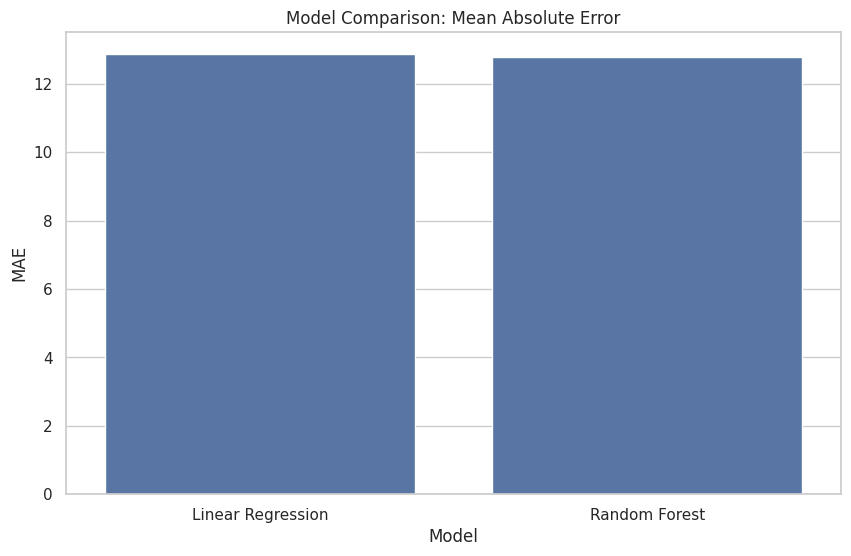

In [30]:
# CELL 30 — Compare machine-learning models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        linear_r2,
        rf_r2
    ]
})

display(model_comparison)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison: Mean Absolute Error")

plt.show()

,Actual,Linear_Predicted,Random_Forest_Predicted,RF_Residual
0,3.66,6.738917,6.278855,-2.618855
1,17.39,1.665162,6.605164,10.784836
2,45.55,3.764779,6.388241,39.161759
3,12.00,5.089921,5.299841,6.700159
4,19.92,8.665670,9.481701,10.438299
5,2.13,16.238999,14.920391,-12.790391
6,25.94,5.787648,5.562699,20.377301
7,8.38,3.235778,6.748268,1.631732
8,1.13,9.697270,8.093349,-6.963349
9,34.88,27.504088,29.187530,5.692470


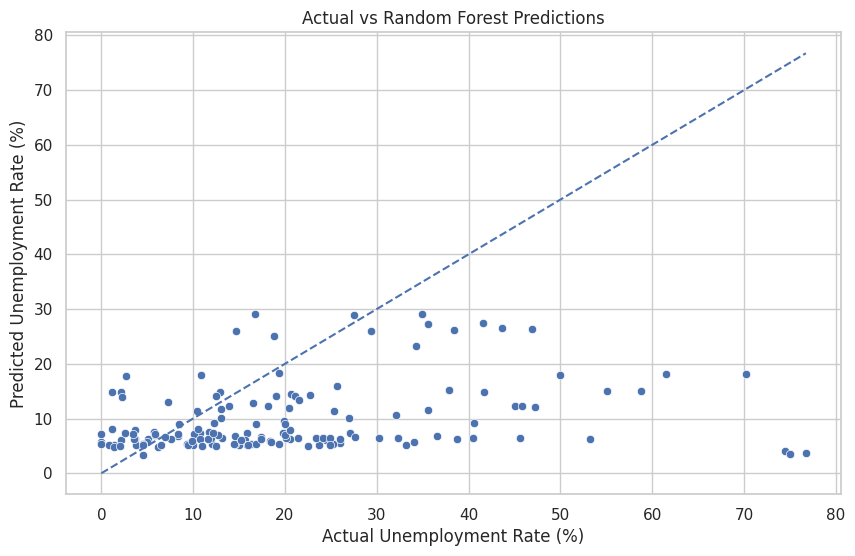

In [31]:
# CELL 31 — Actual versus predicted values

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Linear_Predicted": linear_predictions,
    "Random_Forest_Predicted": rf_predictions
})

comparison["RF_Residual"] = (
    comparison["Actual"] -
    comparison["Random_Forest_Predicted"]
)

display(comparison.head(20))

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=comparison,
    x="Actual",
    y="Random_Forest_Predicted"
)

minimum = min(
    comparison["Actual"].min(),
    comparison["Random_Forest_Predicted"].min()
)

maximum = max(
    comparison["Actual"].max(),
    comparison["Random_Forest_Predicted"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Random Forest Predictions")

plt.xlabel("Actual Unemployment Rate (%)")

plt.ylabel("Predicted Unemployment Rate (%)")

plt.show()

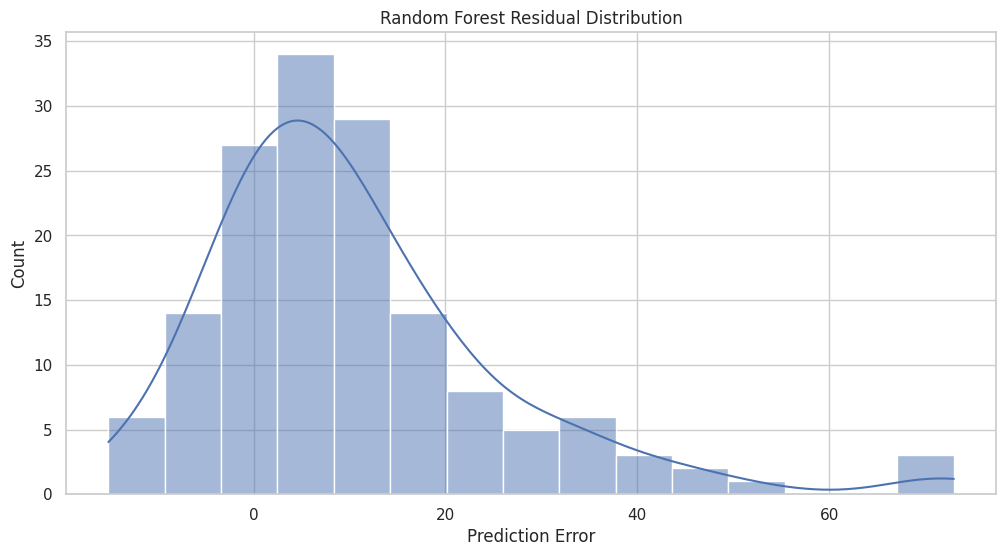

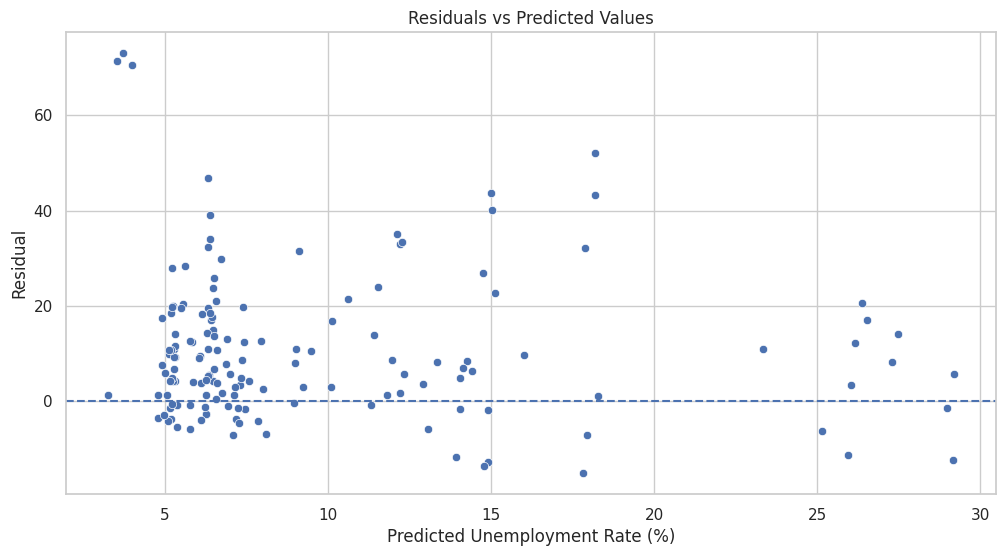

In [32]:
# CELL 32 — Residual analysis

plt.figure(figsize=(12, 6))

sns.histplot(
    comparison["RF_Residual"],
    kde=True
)

plt.title("Random Forest Residual Distribution")

plt.xlabel("Prediction Error")

plt.show()

plt.figure(figsize=(12, 6))

sns.scatterplot(
    x=comparison["Random_Forest_Predicted"],
    y=comparison["RF_Residual"]
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted Values")

plt.xlabel("Predicted Unemployment Rate (%)")

plt.ylabel("Residual")

plt.show()

,0
categorical__Region_Tripura,0.312414
categorical__Region_Haryana,0.168647
numeric__Estimated Employed,0.099764
categorical__Region_Himachal Pradesh,0.095215
numeric__Estimated Labour Participation Rate (%),0.051327
categorical__Region_Jammu & Kashmir,0.045690
categorical__Region_Jharkhand,0.036231
categorical__Region_Bihar,0.035325
categorical__Region_Delhi,0.031693
categorical__Region_Chandigarh,0.028448


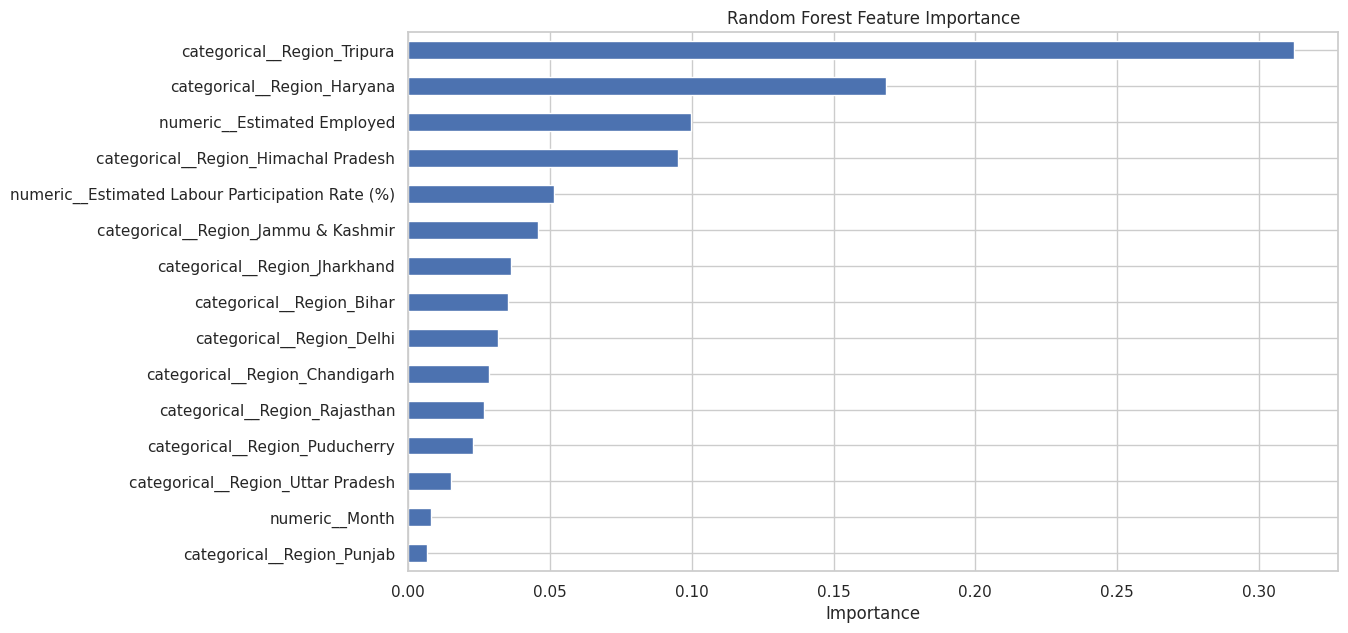

In [33]:
# CELL 33 — Feature importance

rf_estimator = (
    random_forest_model.named_steps["model"]
)

feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.Series(
    rf_estimator.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

display(importance.head(15))

plt.figure(figsize=(12, 7))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance")

plt.show()

## UNSUPERVISED MACHINE LEARNING

In [34]:
# CELL 34 — Prepare regional clustering dataset

regional_data = (
    df.groupby("Region")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Labour Participation Rate (%)",
            "Estimated Employed"
        ]
    ]
    .mean()
    .dropna()
)

display(regional_data.head())

print("Regions available:", len(regional_data))

,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employed
Region,,,
Andhra Pradesh,7.477143,39.375714,8.154093e+06
Assam,6.428077,44.868462,5.354772e+06
Bihar,18.918214,38.153929,1.236619e+07
Chandigarh,15.991667,39.336667,3.168312e+05
Chhattisgarh,9.240357,42.810714,4.303499e+06


Regions available: 28


In [35]:
# CELL 35 — Scale clustering data

cluster_scaler = StandardScaler()

cluster_features = cluster_scaler.fit_transform(
    regional_data
)

print("Regional features scaled successfully.")

Regional features scaled successfully.


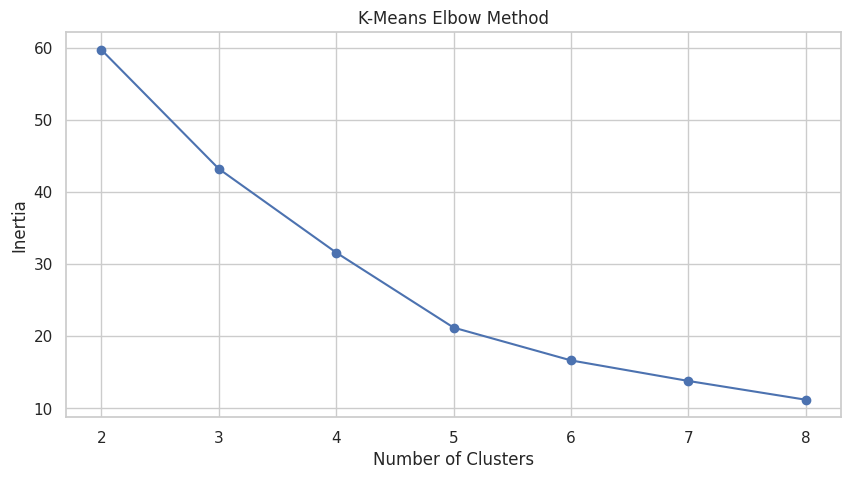

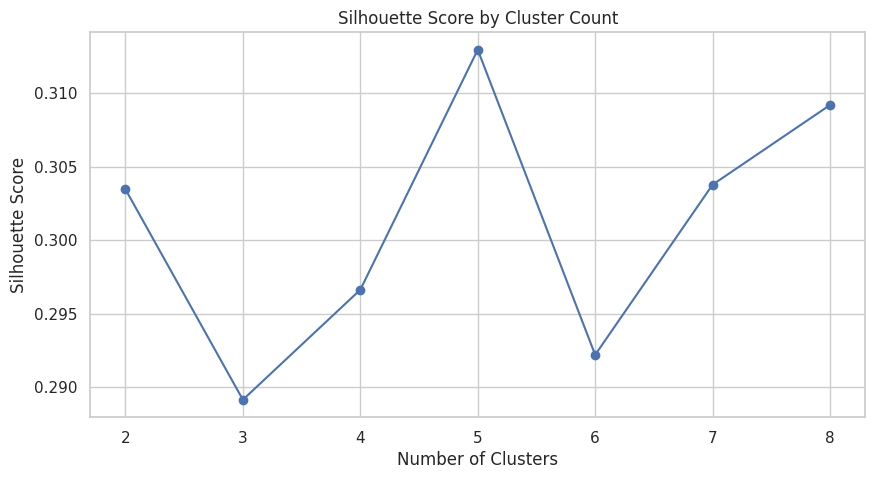

In [36]:
#CELL 36 — Determine suitable cluster count

inertia_values = []

silhouette_values = []

maximum_k = min(8, len(regional_data) - 1)

for k in range(2, maximum_k + 1):

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(cluster_features)

    inertia_values.append(model.inertia_)

    silhouette_values.append(
        silhouette_score(cluster_features, labels)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    range(2, maximum_k + 1),
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Method")

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    range(2, maximum_k + 1),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score by Cluster Count")

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.show()

In [37]:
# CELL 37 — Perform K-Means Clustering
best_k = (range(2, maximum_k + 1))[np.argmax(silhouette_values)]

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

regional_data["Cluster"] = kmeans.fit_predict(cluster_features)

print("Selected clusters:", best_k)

print(
    "Silhouette Score:",
    silhouette_score(
        cluster_features,
        regional_data["Cluster"]
    )
)

display(regional_data)

Selected clusters: 5
Silhouette Score: 0.312962502769286


,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employed,Cluster
Region,,,,
Andhra Pradesh,7.477143,39.375714,8.154093e+06,4
Assam,6.428077,44.868462,5.354772e+06,2
Bihar,18.918214,38.153929,1.236619e+07,0
Chandigarh,15.991667,39.336667,3.168312e+05,0
Chhattisgarh,9.240357,42.810714,4.303499e+06,4
Delhi,16.495357,38.929643,2.627513e+06,0
Goa,9.274167,39.249583,2.263083e+05,4
Gujarat,6.663929,46.101071,1.140201e+07,2
Haryana,26.283214,42.737143,3.557072e+06,0


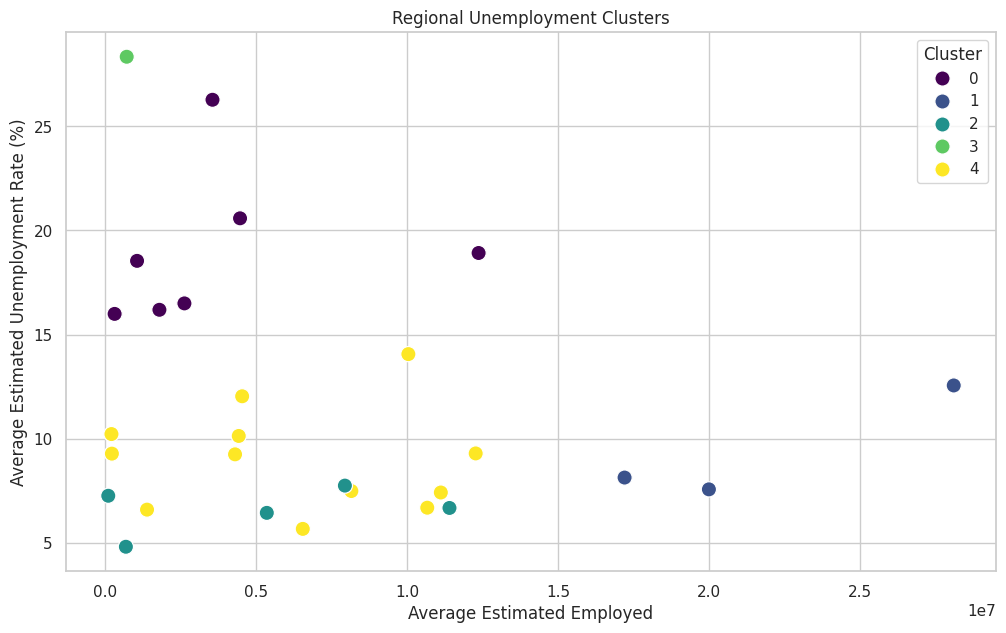

In [39]:
# CELL 38 — Visualise Regional Clusters

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=regional_data,
    x="Estimated Employed",
    y="Estimated Unemployment Rate (%)",
    hue="Cluster",
    palette="viridis",
    s=120
)

plt.title("Regional Unemployment Clusters")
plt.xlabel("Average Estimated Employed")
plt.ylabel("Average Estimated Unemployment Rate (%)")
plt.legend(title="Cluster")
plt.show()

In [41]:
# CELL 39 — Analyse Cluster Profiles

cluster_profile = (
    regional_data.groupby("Cluster")
    .agg({
        "Estimated Unemployment Rate (%)": ["mean", "min", "max"],
        "Estimated Employed": ["mean", "min", "max"],
        "Estimated Labour Participation Rate (%)": ["mean", "min", "max"]
    })
)

print("CLUSTER PROFILE")
display(cluster_profile)

CLUSTER PROFILE


Estimated Unemployment Rate (%)                        \
                                   mean        min        max   
Cluster                                                         
0                             19.000340  15.991667  26.283214   
1                              9.411190   7.557500  12.551429   
2                              6.575633   4.798889   7.737857   
3                             28.350357  28.350357  28.350357   
4                              9.002291   5.657857  14.058214   

        Estimated Employed                              \
                      mean           min           max   
Cluster                                                  
0             3.742372e+06  3.168312e+05  1.236619e+07   
1             2.176119e+07  1.719854e+07  2.809483e+07   
2             5.098613e+06  1.068807e+05  1.140201e+07   
3             7.170026e+05  7.170026e+05  7.170026e+05   
4             6.157552e+06  2.122781e+05  1.226955e+07   

        Estimated Labour Participation Rate (%)                        
                                           mean        min        max  
Cluster                                                                
0                                     40.868741  38.153929  44.222143  
1                                     42.384405  39.432500  45.417500  
2                                     49.424555  44.868462  57.080741  
3                                     61.823929  61.823929  61.823929  
4                                     39.179075  33.775556  42.810714

In [43]:
# CELL 40 — Identify Regions in Each Cluster

for cluster in sorted(regional_data["Cluster"].unique()):
    print(f"\nCLUSTER {cluster}")

    # Use .index to get the Region names since 'Region' is the index of regional_data
    regions = regional_data.loc[
        regional_data["Cluster"] == cluster
    ].index

    print(regions.tolist())


CLUSTER 0
['Bihar', 'Chandigarh', 'Delhi', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand']

CLUSTER 1
['Maharashtra', 'Uttar Pradesh', 'West Bengal']

CLUSTER 2
['Assam', 'Gujarat', 'Meghalaya', 'Sikkim', 'Telangana']

CLUSTER 3
['Tripura']

CLUSTER 4
['Andhra Pradesh', 'Chhattisgarh', 'Goa', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Uttarakhand']


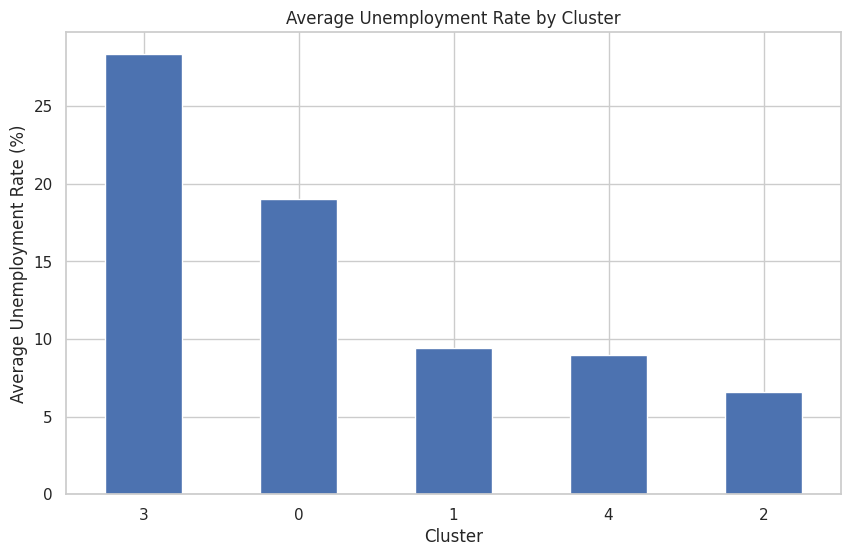

In [45]:
# CELL 41 — Compare Average Unemployment by Cluster

cluster_unemployment = (
    regional_data.groupby("Cluster")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

cluster_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.show()

,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employed,Cluster
Region,,,,
Tripura,28.350357,61.823929,7.170026e+05,3
Haryana,26.283214,42.737143,3.557072e+06,0
Jharkhand,20.585000,41.670714,4.469240e+06,0
Bihar,18.918214,38.153929,1.236619e+07,0
Himachal Pradesh,18.540357,44.222143,1.059824e+06,0


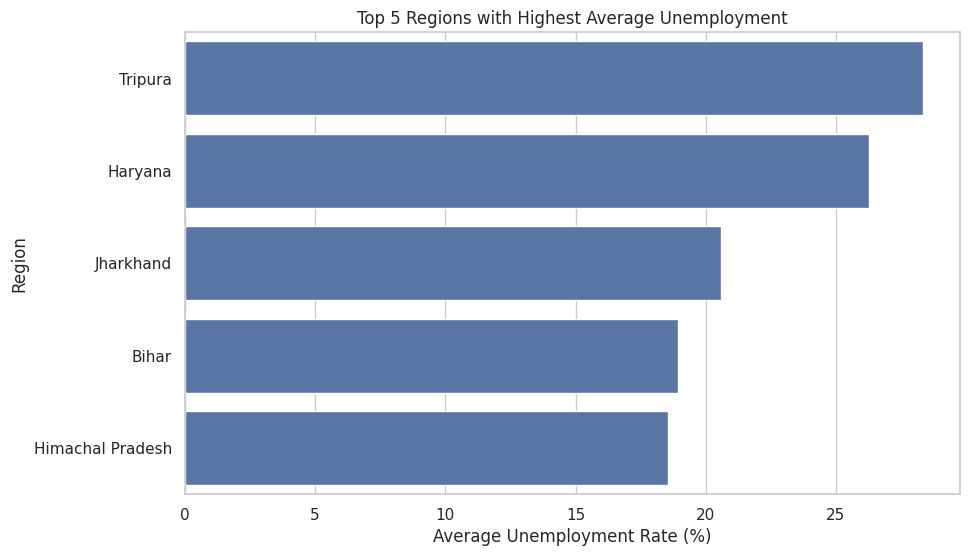

In [47]:
# CELL 42 — Top Five Regions with Highest Unemployment

top_regions = regional_data.sort_values(
    by="Estimated Unemployment Rate (%)",
    ascending=False
).head(5)

display(top_regions)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_regions,
    x="Estimated Unemployment Rate (%)",
    y=top_regions.index
)

plt.title("Top 5 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.show()

,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employed,Cluster
Region,,,,
Meghalaya,4.798889,57.080741,6.897368e+05,2
Odisha,5.657857,38.926429,6.545747e+06,4
Assam,6.428077,44.868462,5.354772e+06,2
Uttarakhand,6.582963,33.775556,1.390228e+06,4
Gujarat,6.663929,46.101071,1.140201e+07,2


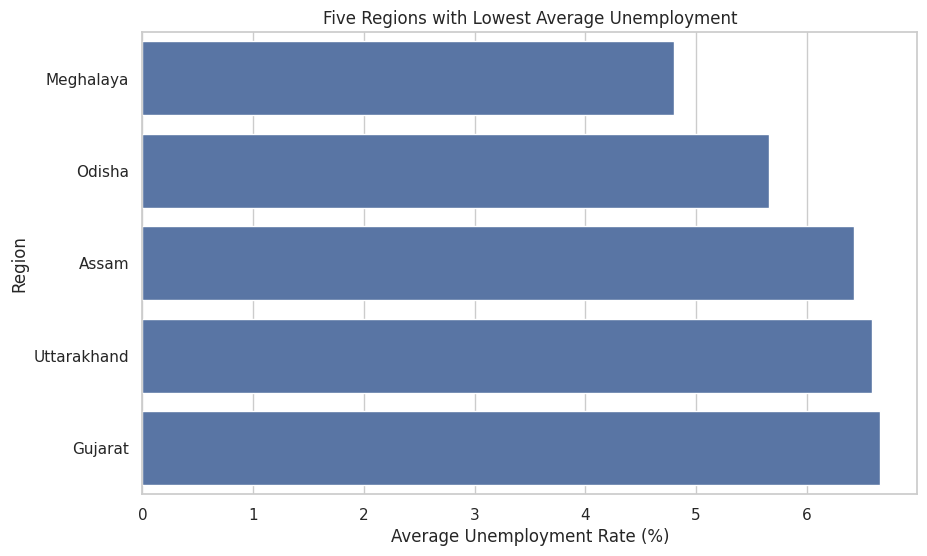

In [50]:
# CELL 43 — Five Regions with Lowest Unemployment

lowest_regions = regional_data.sort_values(
    by="Estimated Unemployment Rate (%)",
    ascending=True
).head(5)

display(lowest_regions)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=lowest_regions,
    x="Estimated Unemployment Rate (%)",
    y=lowest_regions.index
)

plt.title("Five Regions with Lowest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.show()

In [52]:
# CELL 44 — Overall Statistical Analysis

print("OVERALL UNEMPLOYMENT ANALYSIS")
print("=" * 50)

print(
    "Average Unemployment:",
    round(df["Estimated Unemployment Rate (%)"].mean(), 2)
)

print(
    "Maximum Unemployment:",
    round(df["Estimated Unemployment Rate (%)"].max(), 2)
)

print(
    "Minimum Unemployment:",
    round(df["Estimated Unemployment Rate (%)"].min(), 2)
)

if "Area" in df.columns:
    print("\nUnemployment by Area:")
    display(
        df.groupby("Area")["Estimated Unemployment Rate (%)"]
        .mean()
        .sort_values(ascending=False)
    )

OVERALL UNEMPLOYMENT ANALYSIS
Average Unemployment: 11.79
Maximum Unemployment: 76.74
Minimum Unemployment: 0.0

Unemployment by Area:


,Estimated Unemployment Rate (%)
Area,
Urban,13.166614
Rural,10.324791


In [54]:
# CELL 45 — Generate Key Insights

print("KEY PROJECT INSIGHTS")
print("=" * 50)

print(
    f"Average unemployment rate: "
    f"{df['Estimated Unemployment Rate (%)'].mean():.2f}%"
)

print(
    f"Highest unemployment rate: "
    f"{df['Estimated Unemployment Rate (%)'].max():.2f}%"
)

print(
    f"Lowest unemployment rate: "
    f"{df['Estimated Unemployment Rate (%)'].min():.2f}%"
)

print(
    "\nRegion with highest average unemployment:",
    top_regions.index[0]
)

print(
    "Region with lowest average unemployment:",
    lowest_regions.index[0]
)

print(
    "\nNumber of identified clusters:",
    regional_data["Cluster"].nunique()
)

KEY PROJECT INSIGHTS
Average unemployment rate: 11.79%
Highest unemployment rate: 76.74%
Lowest unemployment rate: 0.00%

Region with highest average unemployment: Tripura
Region with lowest average unemployment: Meghalaya

Number of identified clusters: 5


In [55]:
# CELL 46 — Compare Machine Learning Models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

display(model_comparison)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,12.867282,18.840267,-0.365228
1,Random Forest,12.799497,18.678299,-0.341856


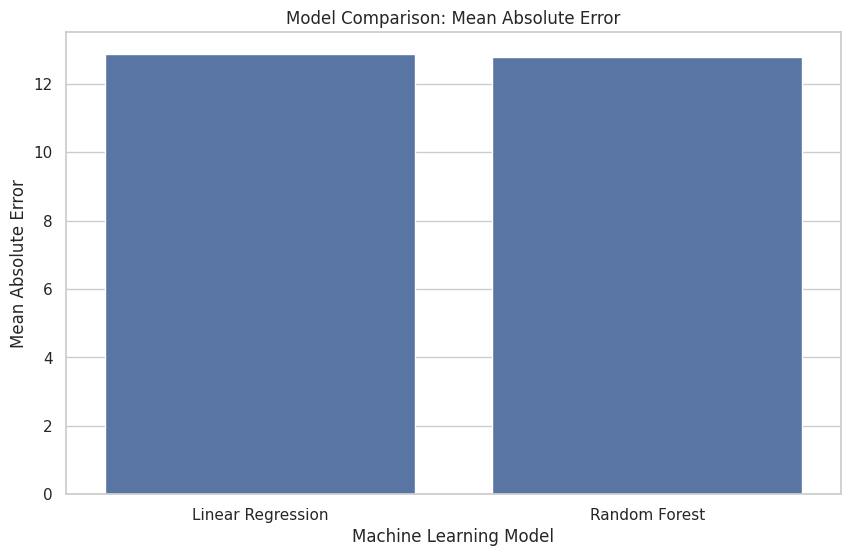

In [56]:
# CELL 47 — Visualise Model Performance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison: Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error")
plt.show()

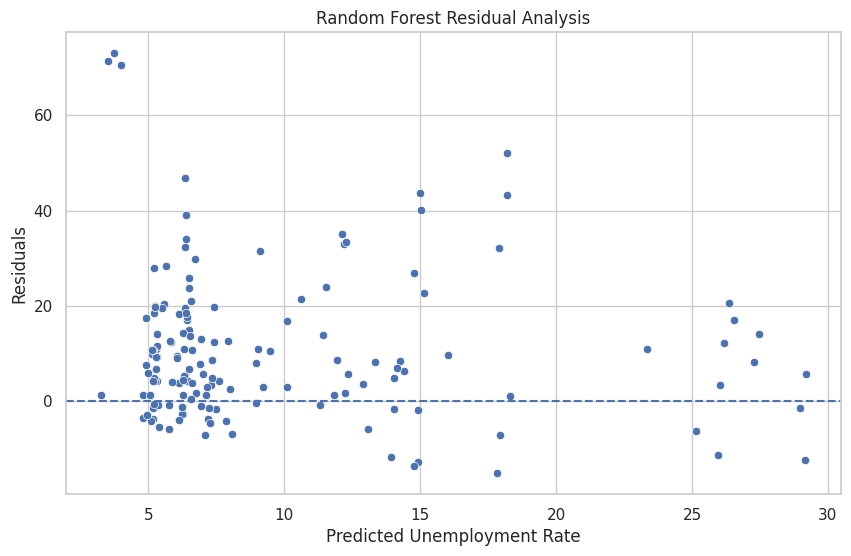

Mean Residual: 10.5101
Residual Standard Deviation: 15.4918


In [57]:
# CELL 48 — Residual Analysis

residuals = y_test - rf_predictions

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=rf_predictions,
    y=residuals
)

plt.axhline(y=0, linestyle="--")

plt.title("Random Forest Residual Analysis")
plt.xlabel("Predicted Unemployment Rate")
plt.ylabel("Residuals")
plt.show()

print("Mean Residual:", round(residuals.mean(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))

In [58]:
# CELL 49 — Export Cleaned Dataset

df.to_csv(
    "cleaned_unemployment_data.csv",
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


In [60]:
# CELL 50 — Export Regional Clustering Results

regional_data.to_csv(
    "regional_clustering_results.csv",
    index=False
)

cluster_profile.to_csv(
    "cluster_profile.csv"
)

print("Regional clustering files exported successfully.")

Regional clustering files exported successfully.


In [61]:
# CELL 51 — Export Model Predictions

prediction_results = pd.DataFrame({
    "Actual_Unemployment": y_test.values,
    "Linear_Regression_Prediction": linear_predictions,
    "Random_Forest_Prediction": rf_predictions
})

prediction_results.to_csv(
    "model_predictions.csv",
    index=False
)

display(prediction_results.head())

,Actual_Unemployment,Linear_Regression_Prediction,Random_Forest_Prediction
0,3.66,6.738917,6.278855
1,17.39,1.665162,6.605164
2,45.55,3.764779,6.388241
3,12.00,5.089921,5.299841
4,19.92,8.665670,9.481701


In [62]:
# CELL 52 — Export Model Performance

model_comparison.to_csv(
    "model_performance.csv",
    index=False
)

print("Model performance exported successfully.")

Model performance exported successfully.


In [63]:
# CELL 53 — Save Machine Learning Models

import joblib

joblib.dump(
    linear_model,
    "linear_regression_model.pkl"
)

joblib.dump(
    random_forest_model,
    "random_forest_model.pkl"
)

joblib.dump(
    kmeans,
    "kmeans_clustering_model.pkl"
)

joblib.dump(
    cluster_scaler,
    "cluster_scaler.pkl"
)

print("Machine learning models saved successfully.")

Machine learning models saved successfully.


In [64]:
# CELL 54 — Package Project Outputs

import zipfile
import os

output_files = [
    "cleaned_unemployment_data.csv",
    "regional_clustering_results.csv",
    "cluster_profile.csv",
    "model_predictions.csv",
    "model_performance.csv",
    "linear_regression_model.pkl",
    "random_forest_model.pkl",
    "kmeans_clustering_model.pkl",
    "cluster_scaler.pkl"
]

with zipfile.ZipFile(
    "Unemployment_Analysis_Project_Outputs.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_files:
        if os.path.exists(file):
            zipf.write(file)

print("Project outputs packaged successfully.")

Project outputs packaged successfully.


In [65]:
# CELL 55 — Download Final Project Outputs

from google.colab import files

files.download(
    "Unemployment_Analysis_Project_Outputs.zip"
)

print("Project download initiated.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project download initiated.
